# Calculadora de salarios para programadores — red neuronal de regresión

Encuesta Stack Overflow 2020, dataset depurado por `limpieza_stackoverflow.py`.

**Problema:** regresión supervisada. A partir del **lenguaje de programación**, los
**años de experiencia profesional** (`YearsCodePro`) y el **país**, la red predice el
**salario anual en USD**.

Este notebook cubre las fases 1 a 6 del plan de `PROPUESTA-RED-NEURONAL.md`: filtrar,
preprocesar, partir los datos, entrenar, evaluar y guardar el modelo para la
calculadora.

> Antes de correrlo hay que generar el dataset limpio:
> `.venv/bin/python limpieza_stackoverflow.py`

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
# Fija la semilla de Python, NumPy y TensorFlow a la vez, y obliga a TensorFlow
# a usar operaciones deterministas: dos corridas dan exactamente la misma red.
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()

SALIDAS = Path("salidas")
ARCHIVO_LIMPIO = SALIDAS / "stackoverflow_limpio.csv"
print("TensorFlow", tf.__version__)

I0000 00:00:1793829775.647970 1571363 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793829777.641656 1571363 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.22.0-rc0


## Fase 1 · Filtrar el dataset

Dos filtros, en este orden:

1. **Solo salarios reportados.** El 45,5 % de las filas recibió la mediana del salario
   (54.049 USD) durante la limpieza porque no respondió esa pregunta. Si entran al
   entrenamiento, la red aprende a contestar ese mismo número para casi cualquier
   entrada. La columna `ConvertedComp_reportado` dice qué salarios son reales; filtrar
   por `== 54049` no sirve, porque 204 personas reportaron justo ese valor.
2. **Sin salarios en 0.** La red se entrena sobre `log(salario)` y `log(0)` no existe.
   Un salario anual de 0 USD tampoco tiene sentido para una calculadora de salario
   laboral.

In [2]:
df = pd.read_csv(ARCHIVO_LIMPIO, low_memory=False)
COLUMNAS_LENGUAJE = sorted(c for c in df.columns if c.startswith("usa_"))
COLUMNA_EXPERIENCIA = "YearsCodePro"
COLUMNA_PAIS = "Country_agrupado"
COLUMNA_OBJETIVO = "ConvertedComp"

reportados = df[df["ConvertedComp_reportado"]]
datos = reportados[reportados[COLUMNA_OBJETIVO] > 0]
datos = datos[COLUMNAS_LENGUAJE + [COLUMNA_EXPERIENCIA, COLUMNA_PAIS, COLUMNA_OBJETIVO]].reset_index(drop=True)

print(f"Dataset limpio:            {len(df):>6} filas")
print(f"Con salario reportado:     {len(reportados):>6} filas")
print(f"Sin salario en 0:          {len(datos):>6} filas  <- tabla de entrenamiento")
print(f"Entradas: {len(COLUMNAS_LENGUAJE)} lenguajes, experiencia, "
      f"{datos[COLUMNA_PAIS].nunique()} categorías de país")

Dataset limpio:             63803 filas
Con salario reportado:      34756 filas
Sin salario en 0:           34614 filas  <- tabla de entrenamiento
Entradas: 25 lenguajes, experiencia, 18 categorías de país


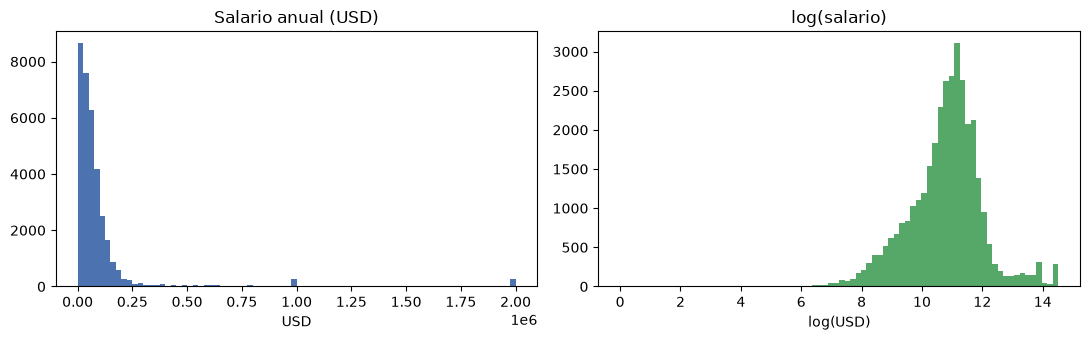

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(datos[COLUMNA_OBJETIVO], bins=80, color="#4c72b0")
ejes[0].set_title("Salario anual (USD)")
ejes[0].set_xlabel("USD")
ejes[1].hist(np.log(datos[COLUMNA_OBJETIVO]), bins=80, color="#55a868")
ejes[1].set_title("log(salario)")
ejes[1].set_xlabel("log(USD)")
plt.tight_layout()
plt.show()

El salario tiene una cola larga hacia la derecha: unos pocos salarios enormes
dominarían la función de pérdida. Su logaritmo queda mucho más concentrado; por eso la
red aprende `log(salario)` y la calculadora devuelve `exp(predicción)` en dólares.

## Fase 2 · Preprocesar

| Entrada | Transformación |
|---|---|
| Lenguajes `usa_*` | Ya son binarias (0/1): pasan sin cambios. |
| `YearsCodePro` | `StandardScaler`: media 0, desviación 1. |
| `Country_agrupado` | *One-hot*: una columna 0/1 por país. |
| Objetivo | `log(ConvertedComp)` |

El `ColumnTransformer` se guarda junto al modelo para que la calculadora transforme
sus entradas exactamente igual que en el entrenamiento.

In [4]:
preprocesador = ColumnTransformer([
    ("lenguajes", "passthrough", COLUMNAS_LENGUAJE),
    ("experiencia", StandardScaler(), [COLUMNA_EXPERIENCIA]),
    ("pais", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [COLUMNA_PAIS]),
])

X = datos[COLUMNAS_LENGUAJE + [COLUMNA_EXPERIENCIA, COLUMNA_PAIS]]
y = np.log(datos[COLUMNA_OBJETIVO].to_numpy())

## Fase 3 · Partir los datos

| Conjunto | % del total | Para qué |
|---|---|---|
| Entrenamiento | 70 % | Ajustar los pesos. |
| Validación | 10 % | Vigilar el sobreajuste y activar el *early stopping*. |
| Prueba | 20 % | Medir el error final una sola vez, con datos que la red nunca vio. |

El preprocesador se ajusta **solo con el entrenamiento**: la media y la desviación de la
experiencia no pueden salir de los datos de prueba (fuga de información).

In [5]:
X_resto, X_prueba, y_resto, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA)
# 12,5 % del 80 % restante = 10 % del total
X_entr, X_val, y_entr, y_val = train_test_split(
    X_resto, y_resto, test_size=0.125, random_state=SEMILLA)

X_entr_t = preprocesador.fit_transform(X_entr).astype("float32")
X_val_t = preprocesador.transform(X_val).astype("float32")
X_prueba_t = preprocesador.transform(X_prueba).astype("float32")

for nombre, conjunto in [("Entrenamiento", X_entr), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre:<14} {len(conjunto):>6} filas  ({len(conjunto) / len(X):.0%})")
print(f"Neuronas de entrada: {X_entr_t.shape[1]}")

Entrenamiento   24229 filas  (70%)
Validación       3462 filas  (10%)
Prueba           6923 filas  (20%)
Neuronas de entrada: 44


## Fase 4 · Construir y entrenar la red

Cada neurona calcula una **suma ponderada** de sus entradas, `z = w·x + b`, y la pasa
por una **activación**. Las capas ocultas usan ReLU, `max(0, z)`, que es lo que le
permite a la red aprender relaciones no lineales (por ejemplo, que el salario sube
rápido los primeros años y luego se aplana). La salida es lineal porque predice un
número cualquiera: el logaritmo del salario.

El entrenamiento minimiza el **error cuadrático medio (MSE)** con el optimizador Adam:
*backpropagation* calcula cuánto contribuye cada peso al error y el **descenso de
gradiente** los corrige poco a poco, lote a lote. El *early stopping* detiene el
entrenamiento cuando el error de validación deja de mejorar durante 10 épocas y se
queda con los mejores pesos.

### Selección de la arquitectura

La propuesta arrancaba con dos capas ocultas (64 y 32 neuronas) y *dropout* de 0,2,
y dejaba abierta la opción de bajar a una sola capa si no mejoraba. Se comparan tres
arquitecturas sobre el conjunto de **validación** (nunca sobre prueba, que se reserva
para la medición final), cada una con tres semillas distintas para que la diferencia
no dependa de la suerte de la inicialización. Como referencia se incluye una
regresión lineal con las mismas entradas.

In [6]:
from sklearn.linear_model import LinearRegression

def construir_red(capas, dropout):
    return tf.keras.Sequential(
        [tf.keras.layers.Input(shape=(X_entr_t.shape[1],))]
        + [tf.keras.layers.Dense(n, activation="relu", name=f"oculta_{i + 1}") for i, n in enumerate(capas)]
        + ([tf.keras.layers.Dropout(dropout, name="dropout")] if dropout else [])
        + [tf.keras.layers.Dense(1, activation="linear", name="salida_log_salario")]
    )

def entrenar(red):
    red.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return red.fit(
        X_entr_t, y_entr, validation_data=(X_val_t, y_val), epochs=200, batch_size=64, verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])

CANDIDATAS = {
    "2 capas (64, 32) + dropout 0,2": ([64, 32], 0.2),
    "2 capas (64, 32) sin dropout": ([64, 32], 0.0),
    "1 capa (32)": ([32], 0.0),
}
filas = []
for nombre, (capas, dropout) in CANDIDATAS.items():
    r2 = []
    for semilla in [1, 2, 3]:
        tf.keras.utils.set_random_seed(semilla)
        red = construir_red(capas, dropout)
        entrenar(red)
        r2.append(r2_score(y_val, red.predict(X_val_t, verbose=0).ravel()))
    filas.append({"arquitectura": nombre, "R² validación (media)": np.mean(r2),
                  "mínimo": min(r2), "máximo": max(r2)})
lineal = LinearRegression().fit(X_entr_t, y_entr)
r2_lineal = r2_score(y_val, lineal.predict(X_val_t))
filas.append({"arquitectura": "Regresión lineal (referencia)", "R² validación (media)": r2_lineal,
              "mínimo": r2_lineal, "máximo": r2_lineal})
pd.DataFrame(filas).set_index("arquitectura").style.format("{:.3f}")

,R² validación (media),mínimo,máximo
arquitectura,,,
"2 capas (64, 32) + dropout 0,2",0.497,0.495,0.500
"2 capas (64, 32) sin dropout",0.485,0.481,0.488
1 capa (32),0.503,0.503,0.504
Regresión lineal (referencia),0.468,0.468,0.468


Las tres redes quedan muy cerca: el techo no lo pone la arquitectura sino la
información de las entradas (solo lenguaje, experiencia y país). La de **una capa
oculta de 32 neuronas** queda arriba con todas las semillas y es la más simple, así que
es la elegida. Que la red supere a la regresión lineal confirma que hay relaciones no
lineales que aprender, aunque la ganancia es moderada.

In [7]:
tf.keras.utils.set_random_seed(SEMILLA)
modelo = construir_red([32], 0.0)
historial = entrenar(modelo)
modelo.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 32)             │         1,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_log_salario (Dense)      │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,421 (17.27 KB)

 Trainable params: 1,473 (5.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,948 (11.52 KB)

In [8]:
mejor_epoca = int(np.argmin(historial.history["val_loss"])) + 1
print(f"Épocas entrenadas: {len(historial.history['loss'])}  ·  mejor época: {mejor_epoca}")

Épocas entrenadas: 32  ·  mejor época: 22


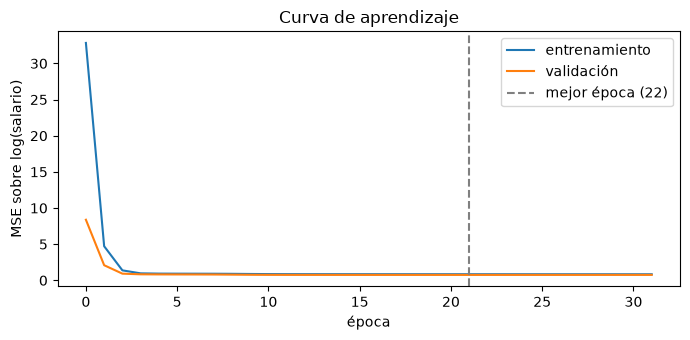

In [9]:
plt.figure(figsize=(7, 3.5))
plt.plot(historial.history["loss"], label="entrenamiento")
plt.plot(historial.history["val_loss"], label="validación")
plt.axvline(mejor_epoca - 1, color="grey", linestyle="--", label=f"mejor época ({mejor_epoca})")
plt.title("Curva de aprendizaje")
plt.xlabel("época")
plt.ylabel("MSE sobre log(salario)")
plt.legend()
plt.tight_layout()
plt.show()

## Fase 5 · Evaluar

Es regresión, así que **no** aplican Accuracy ni F1-Score (son de clasificación). Se usan:

- **MAE:** cuántos dólares se equivoca el modelo en promedio.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **R²:** qué proporción de la variación del salario explica el modelo (0 = nada, 1 = todo).

El MAE y el RMSE se calculan **en dólares**, después de deshacer el logaritmo. El R² se
reporta en las dos escalas: sobre `log(salario)`, que es lo que la red optimiza, y en
dólares, donde unos pocos salarios enormes pesan muchísimo.

Como referencia mínima se usa un **modelo base** que siempre predice la mediana del
salario de entrenamiento: si la red no le gana, no aprendió nada útil.

In [10]:
def metricas(y_log_real, y_log_pred):
    real_usd, pred_usd = np.exp(y_log_real), np.exp(y_log_pred)
    return {
        "MAE (USD)": mean_absolute_error(real_usd, pred_usd),
        "RMSE (USD)": np.sqrt(mean_squared_error(real_usd, pred_usd)),
        "R² log(salario)": r2_score(y_log_real, y_log_pred),
        "R² USD": r2_score(real_usd, pred_usd),
    }

pred_red = modelo.predict(X_prueba_t, verbose=0).ravel()
pred_base = np.full_like(y_prueba, np.median(y_entr))

tabla_metricas = pd.DataFrame({
    "Modelo base (mediana)": metricas(y_prueba, pred_base),
    "Red neuronal": metricas(y_prueba, pred_red),
}).T
tabla_metricas.style.format({"MAE (USD)": "{:,.0f}", "RMSE (USD)": "{:,.0f}",
                             "R² log(salario)": "{:.3f}", "R² USD": "{:.3f}"})

,MAE (USD),RMSE (USD),R² log(salario),R² USD
Modelo base (mediana),"76,955","223,394",-0.011,-0.050
Red neuronal,"60,639","212,720",0.457,0.047


In [11]:
mejora_mae = 1 - tabla_metricas.loc["Red neuronal", "MAE (USD)"] / tabla_metricas.loc["Modelo base (mediana)", "MAE (USD)"]
print(f"La red se equivoca en promedio por {tabla_metricas.loc['Red neuronal', 'MAE (USD)']:,.0f} USD, "
      f"{mejora_mae:.0%} menos que el modelo base.")
print(f"Explica el {tabla_metricas.loc['Red neuronal', 'R² log(salario)']:.0%} de la variación de log(salario).")

La red se equivoca en promedio por 60,639 USD, 21% menos que el modelo base.
Explica el 46% de la variación de log(salario).


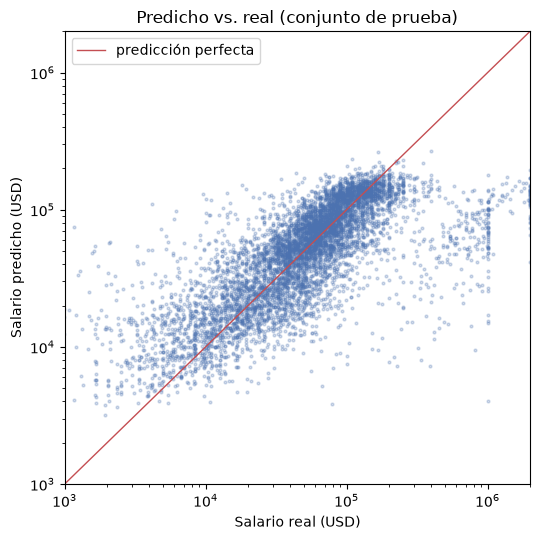

In [12]:
fig, eje = plt.subplots(figsize=(5.5, 5.5))
eje.scatter(np.exp(y_prueba), np.exp(pred_red), s=4, alpha=0.25, color="#4c72b0")
limites = [1_000, 2_000_000]
eje.plot(limites, limites, color="#c44e52", linewidth=1, label="predicción perfecta")
eje.set_xscale("log")
eje.set_yscale("log")
eje.set_xlim(limites)
eje.set_ylim(limites)
eje.set_xlabel("Salario real (USD)")
eje.set_ylabel("Salario predicho (USD)")
eje.set_title("Predicho vs. real (conjunto de prueba)")
eje.legend()
plt.tight_layout()
plt.show()

**Lectura honesta del resultado:** tres variables no explican todo el salario. Faltan
el cargo, el tamaño de la empresa y la formación, entre otras. Por eso la nube de
puntos es ancha y el R² es moderado. El modelo sí captura las diferencias grandes
(país y experiencia), que es lo que necesita una calculadora orientativa.

### ¿Qué tan lejos queda la estimación? Los residuos

El residuo es `log(salario real) − log(salario predicho)`. Si se distribuye como una
normal centrada en 0 con desviación σ, la regla empírica da un rango para cada
estimación: el **68 %** de las personas con ese perfil gana entre `estimación × e^(−σ)`
y `estimación × e^(+σ)`, y el **95 %** entre `estimación × e^(∓1,96σ)`.

σ se calcula con **validación** y se comprueba con **prueba**: si el 68 % de las personas
de prueba cae dentro de ±1σ, el rango que muestra la calculadora es honesto.

La desviación estándar clásica no sirve aquí: unos pocos salarios absurdos (por
ejemplo 1 USD al año) la inflan y la campana sale demasiado ancha. Se usa una **σ
robusta**, `1,4826 × MAD` (la mediana de las desviaciones absolutas, escalada para que
coincida con σ cuando los datos sí son normales), que mide el ancho del centro sin
dejarse arrastrar por los extremos. Las dos se comparan abajo.

In [13]:
residuos_val = y_val - modelo.predict(X_val_t, verbose=0).ravel()
residuos_prueba = y_prueba - pred_red
sigma_clasica = float(residuos_val.std(ddof=1))
SIGMA = float(1.4826 * np.median(np.abs(residuos_val - np.median(residuos_val))))

def dentro(sigma, k):
    return np.mean(np.abs(residuos_prueba) <= k * sigma)

cobertura = pd.DataFrame({
    "esperado (normal)": [0.683, 0.954],
    f"σ clásica = {sigma_clasica:.2f}": [dentro(sigma_clasica, 1), dentro(sigma_clasica, 1.96)],
    f"σ robusta = {SIGMA:.2f}": [dentro(SIGMA, 1), dentro(SIGMA, 1.96)],
}, index=["dentro de ±1σ", "dentro de ±1,96σ"])
print(f"σ robusta = {SIGMA:.3f}  ->  rango del 68 %: ×{np.exp(-SIGMA):.2f} a ×{np.exp(SIGMA):.2f} la estimación")
cobertura.style.format("{:.1%}")

σ robusta = 0.508  ->  rango del 68 %: ×0.60 a ×1.66 la estimación


,esperado (normal),σ clásica = 0.87,σ robusta = 0.51
dentro de ±1σ,68.3%,82.9%,64.9%
"dentro de ±1,96σ",95.4%,93.3%,86.1%


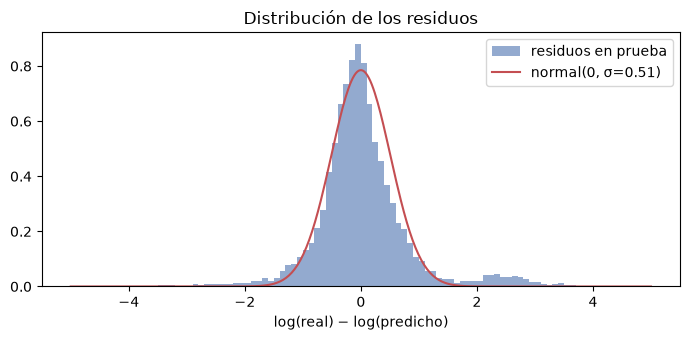

Asimetría: -0.91  ·  curtosis en exceso: 14.00


In [14]:
from scipy import stats

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.hist(residuos_prueba, bins=100, range=(-5, 5), density=True, color="#4c72b0", alpha=0.6,
         label="residuos en prueba")
xs = np.linspace(-5, 5, 400)
eje.plot(xs, stats.norm.pdf(xs, 0, SIGMA), color="#c44e52", label=f"normal(0, σ={SIGMA:.2f})")
eje.set_xlabel("log(real) − log(predicho)")
eje.set_title("Distribución de los residuos")
eje.legend()
plt.tight_layout()
plt.show()
print(f"Asimetría: {stats.skew(residuos_prueba):.2f}  ·  curtosis en exceso: {stats.kurtosis(residuos_prueba):.2f}")

Con la σ robusta, la franja de ±1σ contiene cerca del 68 % de las personas de
prueba, como predice la normal: la campana describe bien el centro. Las colas, en
cambio, son mucho más pesadas que las de una normal (curtosis en exceso alta): ±1,96σ
cubre bastante menos del 95 %, porque hay más personas muy lejos de la estimación de lo
que la normal predice. Por eso la calculadora muestra el rango del 68 %, que sí es
confiable, y no el del 95 %.

### Prueba de la calculadora

La calculadora enciende **un solo lenguaje** (los demás quedan en 0), aunque la red se
entrenó con todos los lenguajes que usa cada persona. Es una simplificación consciente
de la propuesta: más fácil de usar y de explicar.

In [15]:
def estimar_salario(lenguaje, anios_experiencia, pais):
    fila = {c: 0 for c in COLUMNAS_LENGUAJE}
    fila[f"usa_{lenguaje}"] = 1
    fila[COLUMNA_EXPERIENCIA] = anios_experiencia
    fila[COLUMNA_PAIS] = pais
    entrada = preprocesador.transform(pd.DataFrame([fila])).astype("float32")
    return float(np.exp(modelo.predict(entrada, verbose=0)[0, 0]))

ejemplos = [
    ("Python", 2, "India"),
    ("Python", 2, "United States"),
    ("Python", 10, "United States"),
    ("JavaScript", 5, "Germany"),
    ("Java", 5, "Brazil"),
    ("Go", 8, "Otros"),
]
pd.DataFrame(
    [(l, a, p, estimar_salario(l, a, p)) for l, a, p in ejemplos],
    columns=["Lenguaje", "Años exp.", "País", "Salario estimado (USD)"],
).style.format({"Salario estimado (USD)": "{:,.0f}"})

,Lenguaje,Años exp.,País,Salario estimado (USD)
0,Python,2,India,"8,499"
1,Python,2,United States,"102,398"
2,Python,10,United States,"145,273"
3,JavaScript,5,Germany,"71,595"
4,Java,5,Brazil,"16,478"
5,Go,8,Otros,"50,933"


## Fase 6 · Guardar el modelo

La calculadora (fase 7) carga estos archivos de `salidas/`:

- `modelo_salarios.keras`: la red entrenada.
- `preprocesador_salarios.joblib`: el `ColumnTransformer` ya ajustado.
- `calculadora_opciones.json`: las listas de lenguajes y países, las métricas y σ.
- `salarios_referencia.csv`: los salarios reales de la tabla de entrenamiento, para
  mostrar junto a cada estimación lo que gana de verdad la gente con ese perfil.

In [16]:
modelo.save(SALIDAS / "modelo_salarios.keras")
joblib.dump(preprocesador, SALIDAS / "preprocesador_salarios.joblib")

opciones = {
    "lenguajes": [c.removeprefix("usa_") for c in COLUMNAS_LENGUAJE],
    "paises": sorted(datos[COLUMNA_PAIS].unique().tolist()),
    "experiencia_max": float(datos[COLUMNA_EXPERIENCIA].max()),
    "metricas_prueba": {k: float(v) for k, v in tabla_metricas.loc["Red neuronal"].items()},
    "sigma_residuos_log": SIGMA,
}
(SALIDAS / "calculadora_opciones.json").write_text(json.dumps(opciones, ensure_ascii=False, indent=2))
datos.to_csv(SALIDAS / "salarios_referencia.csv", index=False)
print("Guardado en", SALIDAS.resolve())

Guardado en /home/danso/orca/projects/Personal/Estadistica3/salidas
